# EXP-019 — Độ quan trọng và lựa chọn đặc trưng cho Random Forest

**Notebook trình bày và tổng hợp:** [notebooks/experiments/Mai_EXP-019_RF_.ipynb](../../../notebooks/experiments/Mai_EXP-019_RF_.ipynb)

**Người thực hiện:** Mai  
**Ngày lập thực nghiệm:** 22/11/2026  
**So sánh train và test** -22/11/2026    
**Trạng thái:** chuẩn bị thực nghiệm. các bảng điểm được tổng hợp sau khi huấn luyện.

Kiểm tra độ quan trọng của 68 đặc trưng sinh lý. Thử xem Random Forest có thể dùng ít biến đầu vào hơn không. So sánh RF dùng đủ 68 đặc trưng với RF có bước chọn đặc trưng. Hai phiên bản sử dụng cùng cấu hình mô hình, cách chia người và dữ liệu đầu vào.


## 02 — Câu hỏi nghiên cứu

Lựa chọn các đặc trưng có độ quan trọng cao có giúp duy trì hoặc cải thiện khả năng nhận diện stress khi giảm số biến đầu vào không? Những đặc trưng nào thường được chọn khi thay đổi người test?

Giả thuyết đặt ra là một số đặc trưng có thể cung cấp thông tin trùng lặp hoặc ít hữu ích. Tuy nhiên, mức độ quan trọng có thể thay đổi giữa người tham gia và giữa hai bài toán. Xem hiệu quả qua điểm test, số đặc trưng và mức thay đổi của tập biến được chọn.


In [1]:
from pathlib import Path
import json
import hashlib
import subprocess
import shutil
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here=Path.cwd()
repo=next(p for p in (here,*here.parents) if (p/'src/wesad/evaluation.py').is_file())
experiment=repo/'experiments/04_additional/EXP-019_RF'
output=repo/'outputs/exp019_rf_mai_20261122'
train_python=repo/'.venv-g1/Scripts/python.exe'
tasks=['binary','multiclass']
task_names={'binary':'Nhị phân','multiclass':'Ba lớp'}
variants=['full68','selected']
metrics=['macro_f1','balanced_accuracy']


## 03 — Dữ liệu

Đầu vào là bảng physiological68, cùng phiên bản và checksum sử dụng ở các thực nghiệm RF trước. Bảng gồm 15 người và 68 đặc trưng sinh lý. Mã người và mã cửa sổ chỉ phục vụ chia fold và đối chiếu dự đoán.

Nhị phân: 0 là không stress, 1 là stress. Ba lớp: 1 là baseline, 2 là stress, 3 là amusement. Điểm của hai bài toán được trình bày riêng.


In [2]:
defaults=yaml.safe_load((repo/'configs/defaults.yaml').read_text(encoding='utf-8'))
data_path=repo/defaults['features']
schema_path=repo/defaults['schema']
assert hashlib.sha256(data_path.read_bytes()).hexdigest()==defaults['feature_sha256']
schema=json.loads(schema_path.read_text(encoding='utf-8'))
data=pd.read_csv(data_path,dtype={'subject_id':str,'window_id':str})
assert len(schema['feature_columns'])==68
assert set(data.subject_id)==set(defaults['expected_subjects'])
assert not data.duplicated(['subject_id','window_id']).any()
print('Số cửa sổ:',len(data),'| Số người:',data.subject_id.nunique(),'| Số đặc trưng: 68')
display(data.groupby(['subject_id','label_original']).size().unstack(fill_value=0))


Số cửa sổ: 6189 | Số người: 15 | Số đặc trưng: 68


label_original,1,2,3
subject_id,,,
S10,226,135,65
S11,227,126,64
S13,226,124,67
S14,219,126,65
S15,226,128,64
S16,226,125,64
S17,226,135,65
S2,219,113,63
S3,218,118,65


## 04 — Phương pháp đánh giá

- Outer LOSO: 14 người train, 1 người test, đủ 15 outer fold cho từng bài toán.
- Đối chứng `full68`: RF dùng đủ 68 đặc trưng, 100 cây, không giới hạn độ sâu, `max_features="sqrt"`, seed 42, không cân bằng lớp. Cấu hình này tương ứng hướng RF baseline của EXP-005. huấn luyện đối chứng trong cùng lần chạy EXP-019.
- Phiên bản `selected`: thêm `SelectFromModel` với một RF 100 cây để xếp hạng đặc trưng. Bộ phân loại phía sau giữ nguyên cấu hình như đối chứng.
- Chọn số đặc trưng `k ∈ {16, 32, 48, 68}` theo Macro-F1 trung bình của 3 inner GroupKFold. Chỉ dùng outer train.
- Imputation và RF xếp hạng nằm trong pipeline: mỗi inner fold đều học lại từ inner train. Không tính một bảng xếp hạng trên toàn bộ dữ liệu rồi mới chia fold.
- Chọn xong thì refit pipeline trên outer train. Sau đó dự đoán outer test. Không điều chỉnh `k` hoặc RF theo điểm outer test.
- Tính mean và SD mẫu (`ddof=1`) qua 15 người. Điểm train chỉ mô tả độ khớp trên dữ liệu đã học, không thay thế điểm test.

30 outer fold được đánh giá cho hai phiên bản, tạo 60 dòng kết quả. Đây là 30 cặp so sánh, không phải 60 fold độc lập. Giữ RF cố định để xem riêng thay đổi do chọn đặc trưng. EXP-019 không chỉnh tham số RF hay cân bằng lớp cùng lúc.


## 05 — Cấu hình

`SelectFromModel` dùng `threshold=-inf` và `max_features=k` để giữ đúng k đặc trưng có độ quan trọng cao nhất. Độ quan trọng được tính bằng mức giảm độ hỗn tạp của RF học từ train. Biến liên tục và các biến tương quan có thể ảnh hưởng đến giá trị này. Không dùng nó để kết luận quan hệ nhân quả.

Tổng hợp tần suất chọn và độ quan trọng trung bình từ 15 outer train. Dùng bảng này để xem kết quả thay đổi nhiều hay ít giữa các lần chọn. Không dùng ngược bảng tổng hợp để chọn đặc trưng cho các fold.


In [3]:
config={k:defaults[k] for k in ['features','schema','feature_version','feature_sha256','expected_subjects']}
config.update(experiment_id='EXP-019',author='Mai',
    run_date=datetime.now(timezone(timedelta(hours=7))).date().isoformat(),
    tasks=['multiclass','binary'],seed=42,k_candidates=[16,32,48,68],inner_splits=3,
    model_params={'rf':{'n_estimators':100,'max_depth':None,'max_features':'sqrt','random_state':42,'n_jobs':1}},
    balance=False,output_dir=str(output.relative_to(repo)),
    selector='SelectFromModel(RandomForestClassifier)',threshold='-inf',
    source_paths=['src/wesad/data.py','src/wesad/evaluation.py','src/wesad/models.py','src/wesad/utils.py'])
display(config)


{'features': 'data/features/g2_physiological68_group15_20261107/all_subjects.csv',
 'schema': 'data/features/g2_physiological68_group15_20261107/feature_schema.json',
 'feature_version': 'physiological_68_v1',
 'feature_sha256': '2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba',
 'expected_subjects': ['S2',
  'S3',
  'S4',
  'S5',
  'S6',
  'S7',
  'S8',
  'S9',
  'S10',
  'S11',
  'S13',
  'S14',
  'S15',
  'S16',
  'S17'],
 'experiment_id': 'EXP-019',
 'author': 'Mai',
 'run_date': '2026-11-22',
 'tasks': ['multiclass', 'binary'],
 'seed': 42,
 'k_candidates': [16, 32, 48, 68],
 'inner_splits': 3,
 'model_params': {'rf': {'n_estimators': 100,
   'max_depth': None,
   'max_features': 'sqrt',
   'random_state': 42,
   'n_jobs': 1}},
 'balance': False,
 'output_dir': 'outputs\\exp019_rf_mai_20261122',
 'selector': 'SelectFromModel(RandomForestClassifier)',
 'threshold': '-inf',
 'source_paths': ['src/wesad/data.py',
  'src/wesad/evaluation.py',
  'src/wesad/models.py',


## 06 — Huấn luyện

`RUN_TRAIN=True` thực hiện huấn luyện hoặc tiếp tục các fold còn thiếu. `False` chỉ đọc kết quả đã lưu. Các hàm đọc dữ liệu, dựng RF và chia inner fold dùng mã chung trong `src/wesad/`. phần thực thi thêm pipeline chọn đặc trưng và ghi kết quả theo từng cặp so sánh.

Môi trường huấn luyện là `.venv-g1` Python 3.12.14. Checkpoint, dự đoán chi tiết, bảng inner CV và mã thực thi lưu trong `outputs/exp019_rf_mai_20261122/`. Cấu hình, kết quả chính, bảng so sánh và hình được sinh trong thư mục EXP-019 khi chạy notebook.

Checkpoint chỉ được dùng lại khi chữ ký cấu hình, mã thực thi, dữ liệu và môi trường khớp. Khi các yếu tố này thay đổi, sử dụng đường dẫn `output` mới ở phần đầu.


In [4]:
RUN_TRAIN = False
experiment.mkdir(parents=True,exist_ok=True)

worker_code="import sys, json, hashlib, warnings\nfrom pathlib import Path\nfrom time import perf_counter\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import clone\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.feature_selection import SelectFromModel\nfrom sklearn.model_selection import LeaveOneGroupOut, GridSearchCV\nfrom sklearn.metrics import make_scorer, f1_score, balanced_accuracy_score, confusion_matrix\nfrom imblearn.pipeline import Pipeline\nfrom threadpoolctl import threadpool_limits\nfrom wesad.data import load_feature_table\nfrom wesad.models import build_pipeline\nfrom wesad.evaluation import task_target, grouped_inner_splits\nfrom wesad.utils import read_config, write_json, write_csv, read_json, file_hash, fingerprint, environment, provenance, PROJECT_ROOT\n\ncfg=read_config(sys.argv[1]);out=PROJECT_ROOT/cfg['output_dir']\ntable=PROJECT_ROOT/cfg['features'];schema=PROJECT_ROOT/cfg['schema']\nassert file_hash(table)==cfg['feature_sha256']\nframe,columns=load_feature_table(table,schema,cfg['expected_subjects'])\nassert len(columns)==68 and set(frame.subject_id)==set(cfg['expected_subjects'])\nX=frame[columns].astype(float);groups=frame.subject_id\nidentity={'config':cfg,'data_sha256':file_hash(table),'schema_sha256':file_hash(schema),\n 'source_sha256':{n:file_hash(PROJECT_ROOT/n) for n in cfg['source_paths']},'environment':environment()}\nsignature=fingerprint(identity)\nout.mkdir(parents=True,exist_ok=True)\nif (out/'manifest.json').exists():\n    assert read_json(out/'manifest.json')['signature']==signature,'Thay cấu hình hoặc mã: cần output mới'\nwrite_json(out/'manifest.json',{'signature':signature,**identity,'provenance':provenance()})\nallmetrics=[];allpred=[];allimportance=[];allchoices=[]\nfor task in cfg['tasks']:\n    y,labels=task_target(frame,task)\n    for train,test in LeaveOneGroupOut().split(X,y,groups):\n        subject=str(groups.iloc[test].iloc[0]);fold=out/'folds'/task/subject\n        donepath=fold/'complete.json'\n        if donepath.exists():\n            done=read_json(donepath)\n            valid=done['signature']==signature and all((fold/n).exists() and file_hash(fold/n)==h for n,h in done['files'].items())\n        else:valid=False\n        if not valid:\n            start=perf_counter();Xt,yt=X.iloc[train],y.iloc[train]\n            splits,description=grouped_inner_splits(Xt,yt,groups.iloc[train],cfg['inner_splits'])\n            assert not set(groups.iloc[train])&set(groups.iloc[test])\n            full=build_pipeline('rf',cfg)\n            selected=Pipeline([('imputer',clone(full['imputer'])),\n                ('selector',SelectFromModel(RandomForestClassifier(**cfg['model_params']['rf']),threshold=-np.inf)),\n                ('model',clone(full['model']))])\n            search=GridSearchCV(selected,{'selector__max_features':cfg['k_candidates']},cv=splits,\n                scoring=make_scorer(f1_score,labels=labels,average='macro',zero_division=0),\n                n_jobs=1,error_score='raise',refit=True)\n            with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=1):\n                warnings.simplefilter('always')\n                full.fit(Xt,yt);search.fit(Xt,yt)\n                fitted=search.best_estimator_;mask=fitted['selector'].get_support()\n                best_k=int(search.best_params_['selector__max_features'])\n                assert mask.sum()==best_k\n                records=[];predictions=[]\n                for variant,model in [('full68',full),('selected',fitted)]:\n                    a=model.predict(Xt);b=model.predict(X.iloc[test])\n                    records.append({'task':task,'subject_id':subject,'variant':variant,'n_features':68 if variant=='full68' else best_k,\n                        'n_train':len(train),'n_test':len(test),\n                        'macro_f1':float(f1_score(y.iloc[test],b,labels=labels,average='macro',zero_division=0)),\n                        'balanced_accuracy':float(balanced_accuracy_score(y.iloc[test],b)),\n                        'train_macro_f1':float(f1_score(yt,a,labels=labels,average='macro',zero_division=0)),\n                        'train_balanced_accuracy':float(balanced_accuracy_score(yt,a))})\n                    p=frame.iloc[test][['subject_id','window_id']].copy()\n                    p['task']=task;p['variant']=variant;p['y_true']=y.iloc[test].to_numpy();p['y_pred']=b\n                    predictions.append(p)\n                if best_k==68:\n                    assert np.array_equal(predictions[0].y_pred,predictions[1].y_pred)\n            importance=pd.DataFrame({'task':task,'subject_id':subject,'feature':columns,\n                'importance':fitted['selector'].estimator_.feature_importances_,'selected':mask.astype(int)})\n            write_csv(fold/'metrics.csv',pd.DataFrame(records));write_csv(fold/'predictions.csv',pd.concat(predictions,ignore_index=True))\n            write_csv(fold/'importance.csv',importance);write_csv(fold/'inner_cv.csv',pd.DataFrame(search.cv_results_))\n            write_json(fold/'details.json',{'task':task,'subject_id':subject,'outer_train_subjects':sorted(set(groups.iloc[train])),\n                'outer_test_subjects':[subject],'inner_splits':description,'best_k':best_k,'selected_features':list(np.asarray(columns)[mask]),\n                'warnings':sorted(set(str(w.message) for w in caught)),'elapsed_seconds':perf_counter()-start})\n            files=['metrics.csv','predictions.csv','importance.csv','inner_cv.csv','details.json']\n            write_json(donepath,{'signature':signature,'files':{n:file_hash(fold/n) for n in files}})\n            print(task,subject,'k=',best_k,flush=True)\n        else:print(task,subject,'checkpoint hợp lệ',flush=True)\n        detail=read_json(fold/'details.json');cv=pd.read_csv(fold/'inner_cv.csv')\n        assert set(detail['outer_train_subjects'])==set(cfg['expected_subjects'])-{subject}\n        assert detail['outer_test_subjects']==[subject]\n        assert len(detail['inner_splits'])==3\n        validation=[]\n        for split in detail['inner_splits']:\n            a,b=set(split['train_subjects']),set(split['validation_subjects'])\n            assert not a&b and a|b==set(detail['outer_train_subjects']) and subject not in a|b\n            validation.extend(b)\n        assert len(validation)==14 and set(validation)==set(detail['outer_train_subjects'])\n        assert len(cv)==4 and np.isfinite(cv.mean_test_score).all()\n        assert set(cv.param_selector__max_features)==set(cfg['k_candidates'])\n        assert np.allclose(cv[[f'split{i}_test_score' for i in range(3)]].mean(axis=1),cv.mean_test_score,atol=1e-12,rtol=0)\n        assert int(cv.iloc[int(cv.mean_test_score.to_numpy().argmax())].param_selector__max_features)==detail['best_k']\n        m=pd.read_csv(fold/'metrics.csv');p=pd.read_csv(fold/'predictions.csv',dtype={'subject_id':str,'window_id':str})\n        imp=pd.read_csv(fold/'importance.csv')\n        assert len(imp)==68 and list(imp.feature)==columns and int(imp.selected.sum())==detail['best_k']\n        assert set(imp.loc[imp.selected.eq(1),'feature'])==set(detail['selected_features'])\n        assert len(m)==2 and set(m.variant)=={'full68','selected'}\n        for r in m.itertuples():\n            part=p.loc[p.variant.eq(r.variant)]\n            assert not part.duplicated(['subject_id','window_id']).any()\n            truth=frame.iloc[test][['subject_id','window_id']].copy();truth['expected']=y.iloc[test].to_numpy()\n            joined=truth.merge(part,on=['subject_id','window_id'],how='outer',validate='one_to_one',indicator=True)\n            assert joined['_merge'].eq('both').all() and joined.expected.eq(joined.y_true).all()\n            assert len(part)==r.n_test and part.y_pred.isin(labels).all()\n            assert abs(f1_score(part.y_true,part.y_pred,labels=labels,average='macro',zero_division=0)-r.macro_f1)<1e-12\n            assert abs(balanced_accuracy_score(part.y_true,part.y_pred)-r.balanced_accuracy)<1e-12\n        allmetrics.append(m);allpred.append(p);allimportance.append(imp)\n        allchoices.append({'task':task,'subject_id':subject,'k':detail['best_k']})\nresults=pd.concat(allmetrics,ignore_index=True);pred=pd.concat(allpred,ignore_index=True)\nimportance=pd.concat(allimportance,ignore_index=True)\nassert len(results)==60 and len(pred)==len(frame)*4\nassert not results.duplicated(['task','subject_id','variant']).any()\nassert not pred.duplicated(['task','subject_id','window_id','variant']).any()\nfor task in cfg['tasks']:\n    _,labels=task_target(frame,task)\n    for variant in ['full68','selected']:\n        part=pred.loc[pred.task.eq(task)&pred.variant.eq(variant)]\n        write_json(out/f'confusion_{task}_{variant}.json',{'labels':labels,'matrix':confusion_matrix(part.y_true,part.y_pred,labels=labels).tolist()})\nfull=results.loc[results.variant.eq('full68')];selected=results.loc[results.variant.eq('selected')]\ncomparison=full.merge(selected,on=['task','subject_id'],validate='one_to_one',suffixes=('_full','_selected'))\nfor metric in ['macro_f1','balanced_accuracy']:comparison[metric+'_delta']=comparison[metric+'_selected']-comparison[metric+'_full']\nstability=importance.groupby(['task','feature']).agg(importance_mean=('importance','mean'),importance_std=('importance','std'),selected_count=('selected','sum')).reset_index()\nstability['selected_fraction']=stability.selected_count/15\nwrite_csv(out/'results.csv',results);write_csv(out/'predictions.csv',pred);write_csv(out/'comparison_full68.csv',comparison)\nwrite_csv(out/'importance_by_fold.csv',importance);write_csv(out/'feature_stability.csv',stability);write_csv(out/'selected_k.csv',pd.DataFrame(allchoices))\nwrite_json(out/'verification.json',{'status':'passed','outer_folds':30,'paired_result_rows':60,'n_predictions':len(pred),\n 'signature':signature,'data_sha256':cfg['feature_sha256'],'metric_scope':'test metrics recomputed from OOF; train metrics recorded during fit'})\nprint('EXP-019: hoàn tất 30 outer fold, 60 dòng kết quả.',flush=True)"

config['worker_sha256']=hashlib.sha256(worker_code.encode('utf-8')).hexdigest()
config_path=experiment/'config.yaml'
config_path.write_text(yaml.safe_dump(config,sort_keys=False,allow_unicode=True),encoding='utf-8')
if RUN_TRAIN:
    output.mkdir(parents=True,exist_ok=True)
    (output/'training_code.py').write_text(worker_code,encoding='utf-8')
    subprocess.run([str(train_python),'-X','utf8','-c',worker_code,str(config_path)],cwd=repo,check=True)
else:
    print('Đọc kết quả đã lưu; không thực hiện huấn luyện.')


Đọc kết quả đã lưu; không thực hiện huấn luyện.


## 07 — Kết quả

`results.csv` lưu điểm train và test theo task, người và phiên bản. `comparison_full68.csv` lưu chênh lệch giữa phiên bản chọn đặc trưng với đối chứng đủ 68 biến. `feature_stability.csv` mô tả độ quan trọng và tần suất lựa chọn qua 15 outer train. Kiểm tra kết quả xong mới ghi các bảng.


In [5]:
proof=json.loads((output/'verification.json').read_text(encoding='utf-8'))
assert proof['status']=='passed' and proof['outer_folds']==30
results=pd.read_csv(output/'results.csv')
comparison=pd.read_csv(output/'comparison_full68.csv')
stability=pd.read_csv(output/'feature_stability.csv')
choices=pd.read_csv(output/'selected_k.csv')
assert len(results)==60 and len(comparison)==len(choices)==30
for name in ['results.csv','comparison_full68.csv','feature_stability.csv']:
    shutil.copy2(output/name,experiment/name)
summary=results.groupby(['task','variant'])[metrics+['train_macro_f1','train_balanced_accuracy','n_features']].agg(['mean','std'])
display(summary.round(4));display(choices)


macro_f1         balanced_accuracy         train_macro_f1  \
                        mean     std              mean     std           mean   
task       variant                                                              
binary     full68     0.8735  0.1440            0.8865  0.1143            1.0   
           selected   0.8757  0.1440            0.8902  0.1147            1.0   
multiclass full68     0.6480  0.1297            0.6700  0.1204            1.0   
           selected   0.6024  0.1478            0.6313  0.1288            1.0   

                         train_balanced_accuracy      n_features           
                     std                    mean  std       mean      std  
task       variant                                                         
binary     full68    0.0                     1.0  0.0    68.0000   0.0000  
           selected  0.0                     1.0  0.0    47.4667  18.8144  
multiclass full68    0.0                     1.0  0.0    68.0000   0.0000  
           selected  0.0                     1.0  0.0    53.0667  17.8544

,task,subject_id,k
0,multiclass,S10,48
1,multiclass,S11,68
2,multiclass,S13,68
3,multiclass,S14,68
4,multiclass,S15,16
5,multiclass,S16,48
6,multiclass,S17,48
7,multiclass,S2,48
8,multiclass,S3,48
9,multiclass,S4,68


## 08 — Biểu đồ

Các hình được tạo từ kết quả thực thi và lưu tại `figures/`. Thanh sai số ở biểu đồ điểm là SD giữa người. Độ quan trọng và tần suất lựa chọn được trình bày riêng để phân biệt mức đóng góp và tính ổn định của từng đặc trưng.


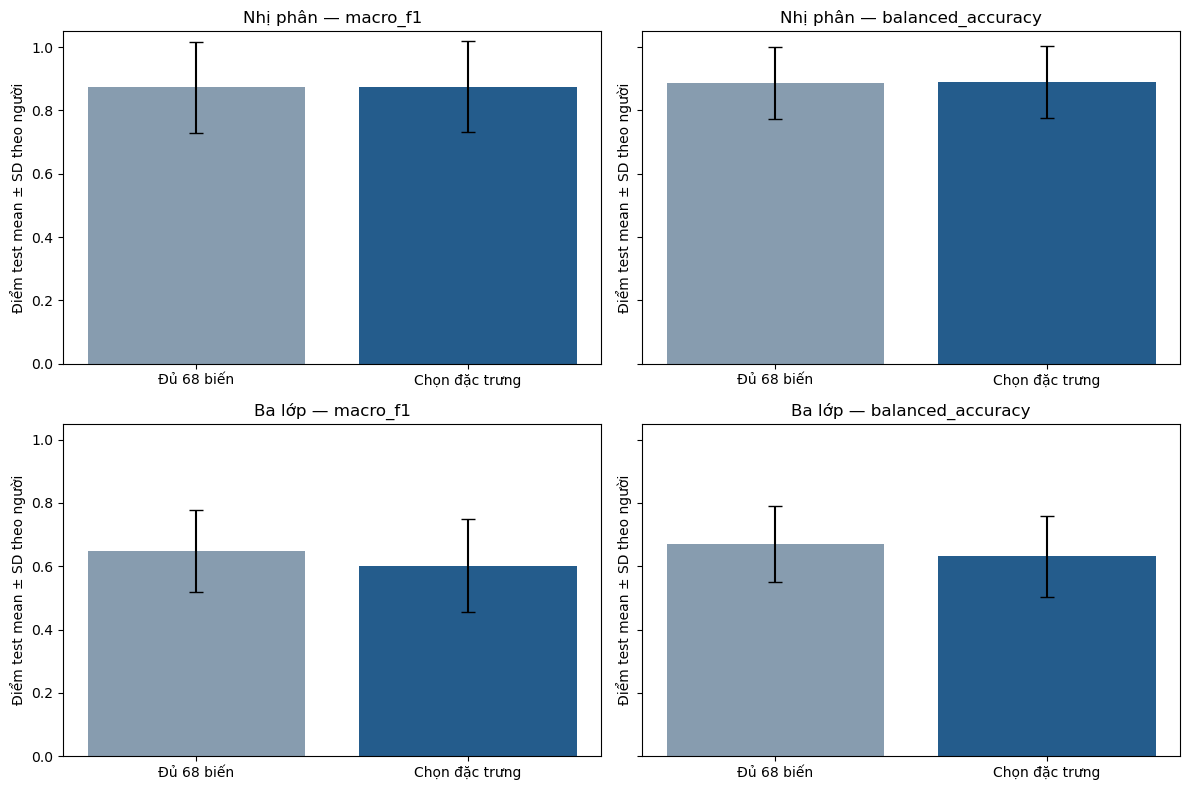

In [6]:
figures=experiment/'figures';figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})
fig,axes=plt.subplots(2,2,figsize=(12,8),sharey=True)
for i,task in enumerate(tasks):
    for j,metric in enumerate(metrics):
        part=results.loc[results.task.eq(task)].groupby('variant')[metric].agg(['mean','std']).loc[variants]
        axes[i,j].bar(['Đủ 68 biến','Chọn đặc trưng'],part['mean'],yerr=part['std'],capsize=5,color=['#879CAF','#245C8C'])
        axes[i,j].set_title(f'{task_names[task]} — {metric}');axes[i,j].set_ylim(0,1.05)
        axes[i,j].set_ylabel('Điểm test mean ± SD theo người')
fig.tight_layout();fig.savefig(figures/'rf_full68_vs_selected.png',dpi=150,bbox_inches='tight');plt.show()


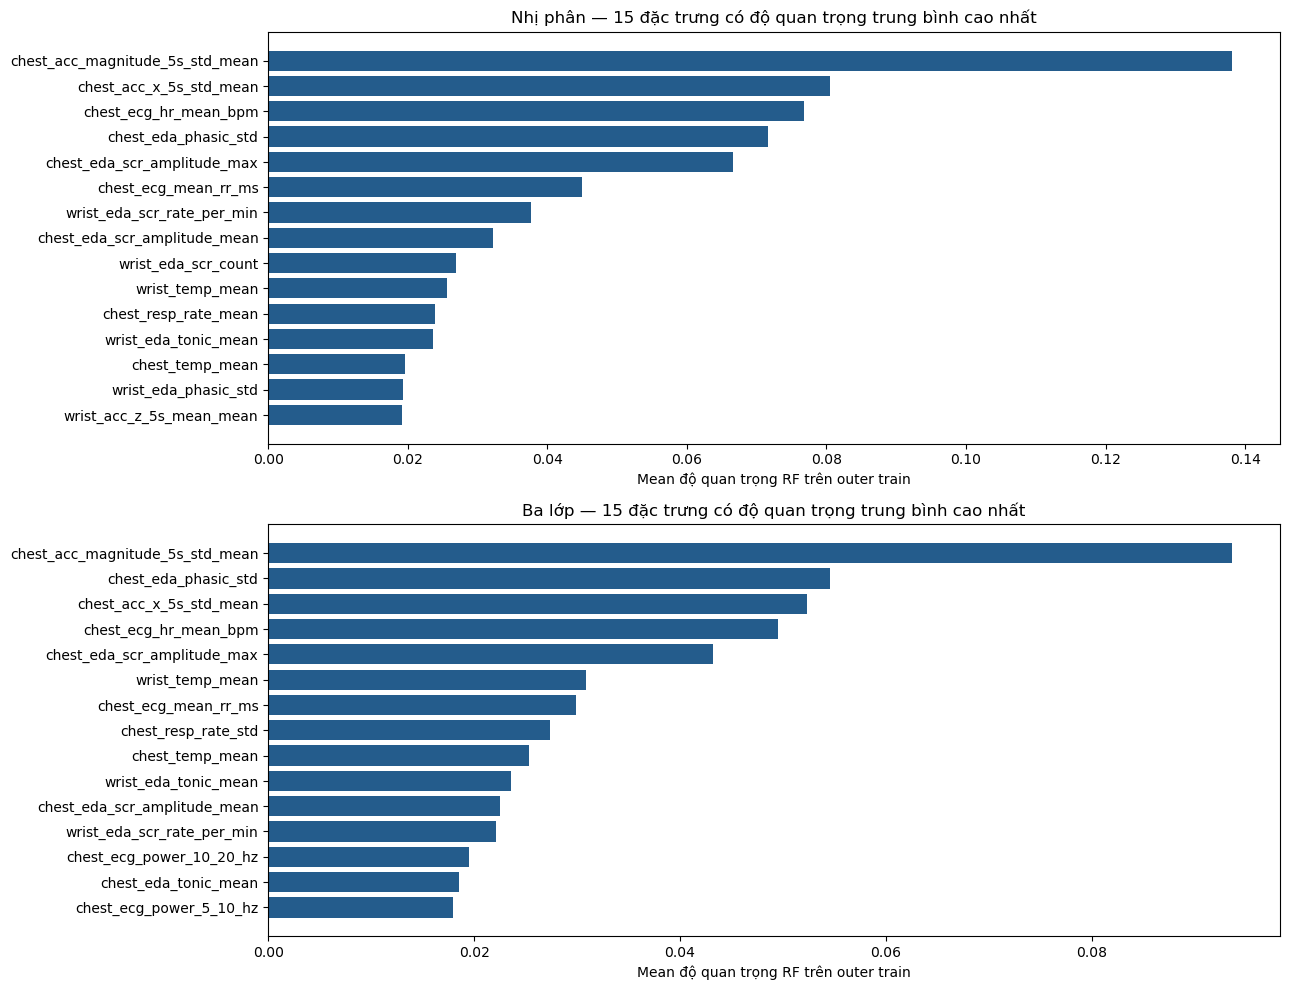

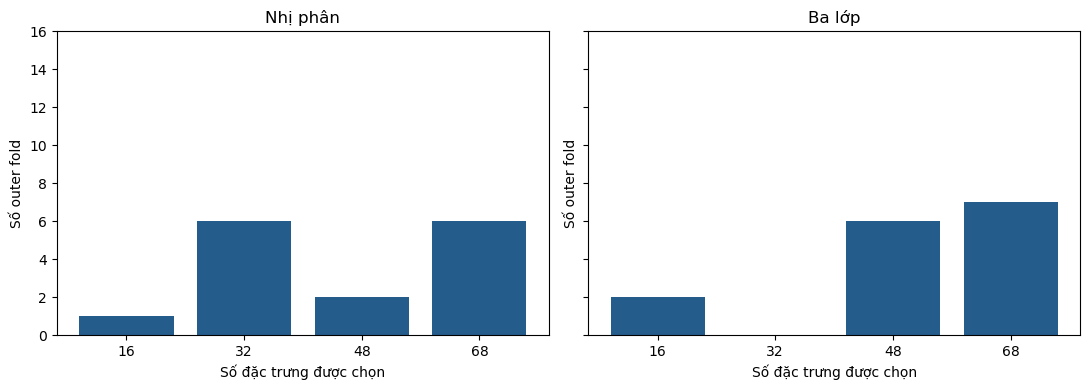

In [7]:
fig,axes=plt.subplots(2,1,figsize=(13,10))
for ax,task in zip(axes,tasks):
    top=stability.loc[stability.task.eq(task)].nlargest(15,'importance_mean').sort_values('importance_mean')
    ax.barh(top.feature,top.importance_mean,color='#245C8C')
    ax.set_title(f'{task_names[task]} — 15 đặc trưng có độ quan trọng trung bình cao nhất')
    ax.set_xlabel('Mean độ quan trọng RF trên outer train')
fig.tight_layout();fig.savefig(figures/'rf_feature_importance.png',dpi=150,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)
for ax,task in zip(axes,tasks):
    counts=choices.loc[choices.task.eq(task)].k.value_counts().reindex(config['k_candidates'],fill_value=0)
    ax.bar(counts.index.astype(str),counts,color='#245C8C');ax.set_title(task_names[task])
    ax.set_xlabel('Số đặc trưng được chọn');ax.set_ylabel('Số outer fold');ax.set_ylim(0,16)
fig.tight_layout();fig.savefig(figures/'rf_selected_k.png',dpi=150,bbox_inches='tight');plt.show()


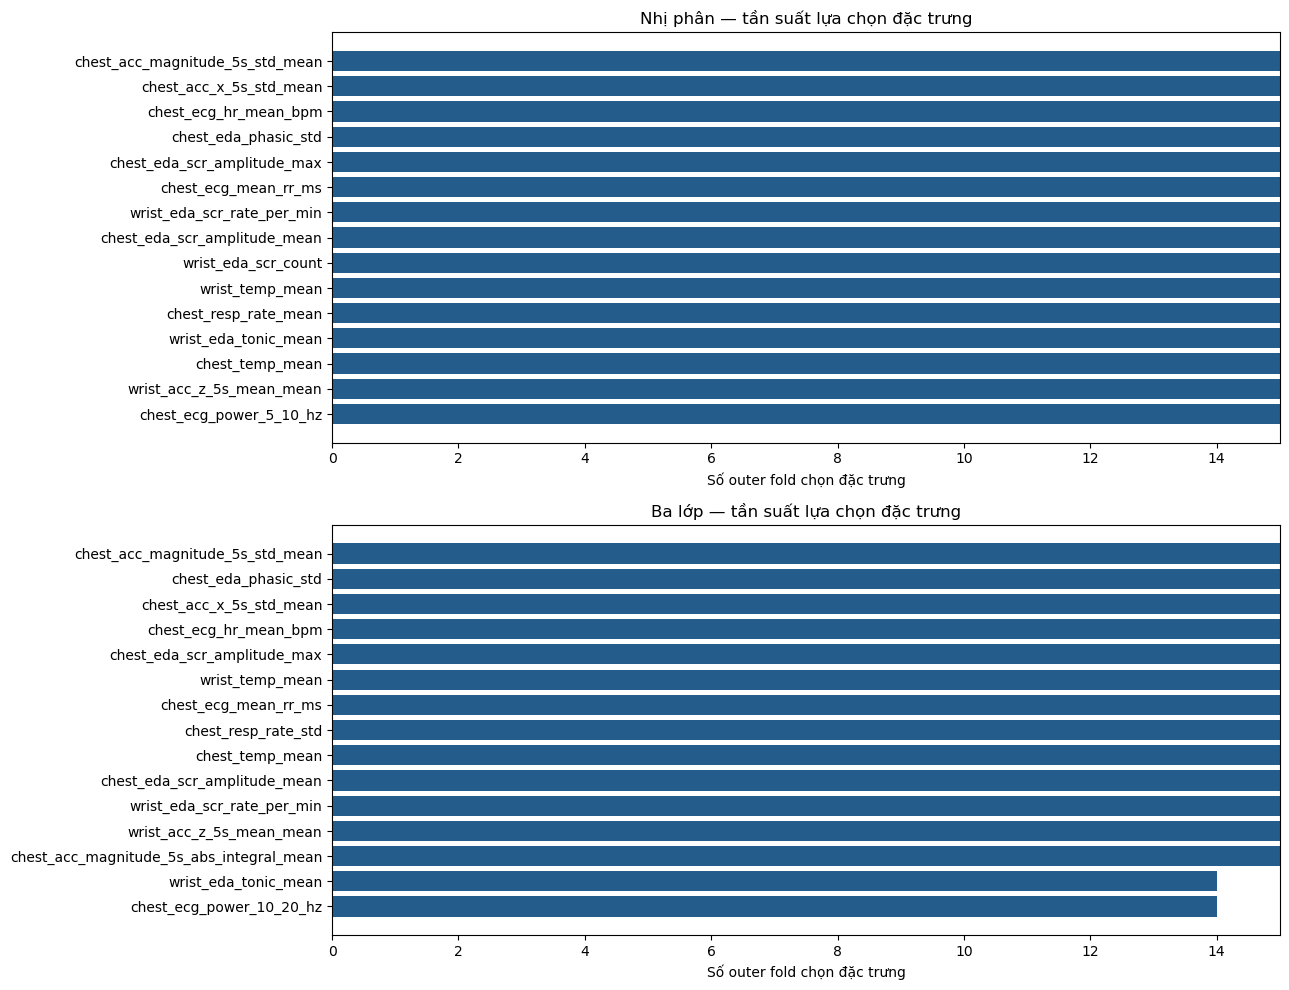

In [8]:
fig,axes=plt.subplots(2,1,figsize=(13,10))
for ax,task in zip(axes,tasks):
    top=stability.loc[stability.task.eq(task)].sort_values(['selected_count','importance_mean'],ascending=False).head(15)
    top=top.iloc[::-1]
    ax.barh(top.feature,top.selected_count,color='#245C8C')
    ax.set_xlim(0,15);ax.set_xlabel('Số outer fold chọn đặc trưng')
    ax.set_title(f'{task_names[task]} — tần suất lựa chọn đặc trưng')
fig.tight_layout();fig.savefig(figures/'rf_feature_selection_frequency.png',dpi=150,bbox_inches='tight');plt.show()


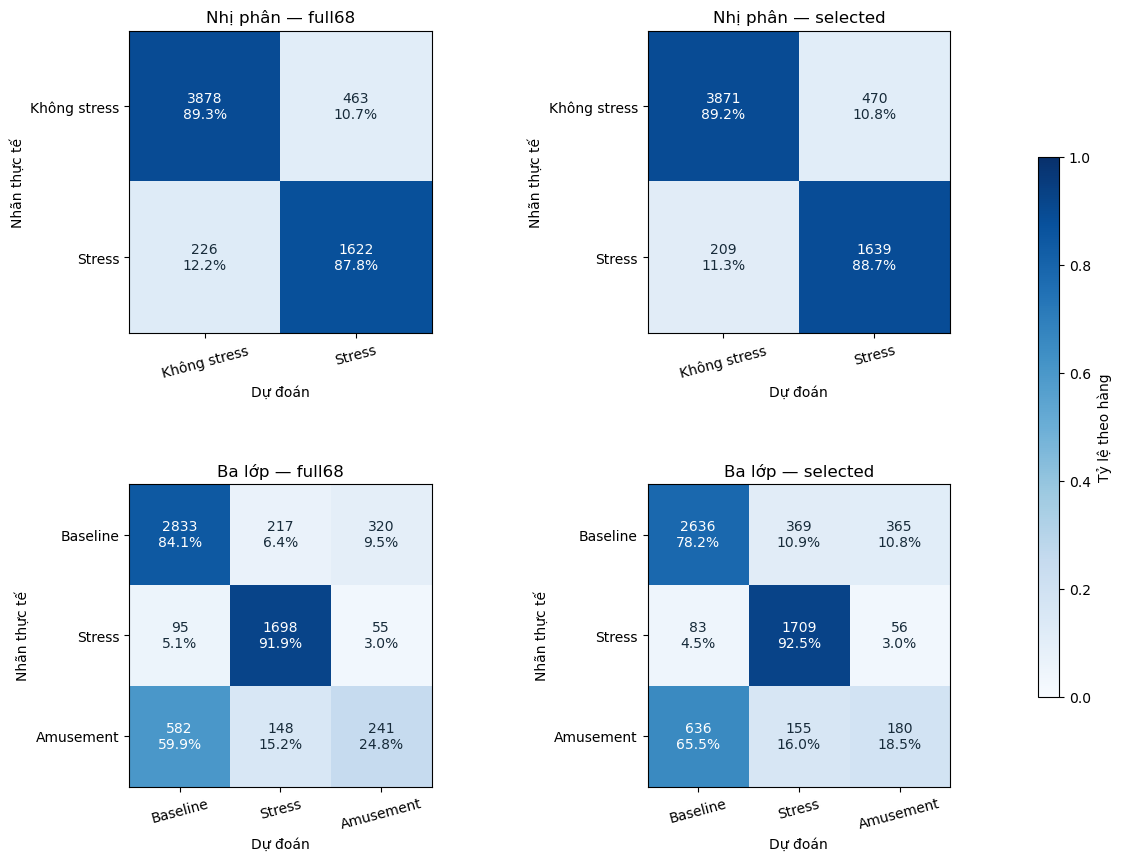

In [9]:
fig,axes=plt.subplots(2,2,figsize=(12,9))
for i,task in enumerate(tasks):
    names=['Không stress','Stress'] if task=='binary' else ['Baseline','Stress','Amusement']
    for j,variant in enumerate(variants):
        saved=json.loads((output/f'confusion_{task}_{variant}.json').read_text(encoding='utf-8'))
        matrix=np.asarray(saved['matrix']);norm=matrix/matrix.sum(axis=1,keepdims=True)
        ax=axes[i,j];im=ax.imshow(norm,cmap='Blues',vmin=0,vmax=1)
        for a in range(len(names)):
            for b in range(len(names)):
                ax.text(b,a,f'{matrix[a,b]}\n{norm[a,b]:.1%}',ha='center',va='center',color='white' if norm[a,b]>.55 else '#172B3A')
        ax.set_xticks(range(len(names)),names,rotation=15);ax.set_yticks(range(len(names)),names)
        ax.set_xlabel('Dự đoán');ax.set_ylabel('Nhãn thực tế');ax.set_title(f'{task_names[task]} — {variant}')
fig.subplots_adjust(left=.12,right=.85,bottom=.10,top=.94,wspace=.45,hspace=.5)
cax=fig.add_axes([.90,.20,.018,.60]);fig.colorbar(im,cax=cax,label='Tỷ lệ theo hàng')
fig.savefig(figures/'rf_selection_confusion_matrices.png',dpi=150,bbox_inches='tight');plt.show()


## 09 — Phân tích

Xem thay đổi điểm test, số biến giữ lại và sự khác biệt giữa người tham gia. Một tập nhỏ đạt điểm tương đương có thể thuận lợi cho xử lý đầu vào, nhưng chi phí RF xếp hạng và inner CV cũng cần được cân nhắc. Giảm số biến không mặc nhiên làm toàn bộ quá trình huấn luyện nhanh hơn.

Các đặc trưng tương quan có thể thay thế nhau giữa các fold. Tần suất lựa chọn thấp không đủ để kết luận một đặc trưng không có giá trị. Kết quả chỉ phản ánh bảng physiological68, các cấu hình đã xác định và giao thức LOSO đang sử dụng.


In [10]:
paragraphs=[]
for task in tasks:
    part=comparison.loc[comparison.task.eq(task)]
    k=choices.loc[choices.task.eq(task)].k
    wins=int(part.macro_f1_delta.gt(1e-10).sum());losses=int(part.macro_f1_delta.lt(-1e-10).sum())
    weak=part.loc[part.macro_f1_selected.idxmin()]
    paragraphs.append(f"### {task_names[task]}\nMacro-F1 thay đổi {part.macro_f1_delta.mean():+.4f}; Balanced Accuracy thay đổi {part.balanced_accuracy_delta.mean():+.4f}. Macro-F1 tăng ở {wins}/15 người, giảm ở {losses}/15 người. Số biến trung bình được giữ là {k.mean():.1f}/68. Fold có Macro-F1 sau lựa chọn thấp nhất: {weak.subject_id} ({weak.macro_f1_selected:.4f}).")
display(Markdown('\n\n'.join(paragraphs)))
display(stability.sort_values(['task','selected_count','importance_mean'],ascending=[True,False,False]).groupby('task').head(15))
display(results.groupby(['task','variant'])[['train_macro_f1','macro_f1','train_balanced_accuracy','balanced_accuracy']].mean().round(4))


### Nhị phân
Macro-F1 thay đổi +0.0022; Balanced Accuracy thay đổi +0.0037. Macro-F1 tăng ở 3/15 người, giảm ở 3/15 người. Số biến trung bình được giữ là 47.5/68. Fold có Macro-F1 sau lựa chọn thấp nhất: S10 (0.5044).

### Ba lớp
Macro-F1 thay đổi -0.0456; Balanced Accuracy thay đổi -0.0387. Macro-F1 tăng ở 1/15 người, giảm ở 7/15 người. Số biến trung bình được giữ là 53.1/68. Fold có Macro-F1 sau lựa chọn thấp nhất: S10 (0.1975).

,task,feature,importance_mean,importance_std,selected_count,selected_fraction
2,binary,chest_acc_magnitude_5s_std_mean,0.138087,0.008147,15,1.000000
5,binary,chest_acc_x_5s_std_mean,0.080518,0.007108,15,1.000000
12,binary,chest_ecg_hr_mean_bpm,0.076709,0.012737,15,1.000000
22,binary,chest_eda_phasic_std,0.071654,0.008487,15,1.000000
23,binary,chest_eda_scr_amplitude_max,0.066623,0.008567,15,1.000000
14,binary,chest_ecg_mean_rr_ms,0.044920,0.005462,15,1.000000
63,binary,wrist_eda_scr_rate_per_min,0.037662,0.006575,15,1.000000
24,binary,chest_eda_scr_amplitude_mean,0.032159,0.006239,15,1.000000
62,binary,wrist_eda_scr_count,0.026945,0.006407,15,1.000000
66,binary,wrist_temp_mean,0.025616,0.006820,15,1.000000


train_macro_f1  macro_f1  train_balanced_accuracy  \
task       variant                                                       
binary     full68               1.0    0.8735                      1.0   
           selected             1.0    0.8757                      1.0   
multiclass full68               1.0    0.6480                      1.0   
           selected             1.0    0.6024                      1.0   

                     balanced_accuracy  
task       variant                      
binary     full68               0.8865  
           selected             0.8902  
multiclass full68               0.6700  
           selected             0.6313

## 10 — Kết luận và nguồn kết quả

Xem kết quả dựa trên điểm test của từng bài toán và số đặc trưng được chọn. Chỉ dùng bảng xếp hạng tổng hợp để mô tả kết quả các fold. Không dùng bảng này để chọn lại đặc trưng theo người test. Chênh lệch quan sát chưa được kiểm định ý nghĩa thống kê.

Thử nghiệm này kiểm tra cách chọn đặc trưng. Chưa chốt tập đặc trưng hoặc huấn luyện mô hình triển khai cuối cùng. Thông tin dữ liệu, môi trường, mã thực thi và checksum từng checkpoint được lưu trong `outputs/`.


In [11]:
lines=[]
for task in tasks:
    part=comparison.loc[comparison.task.eq(task)]
    delta=part.macro_f1_delta.mean();direction='tăng' if delta>1e-10 else 'giảm' if delta< -1e-10 else 'không đổi'
    mean_k=choices.loc[choices.task.eq(task)].k.mean()
    lines.append(f'- **{task_names[task]}:** Macro-F1 trung bình {direction} ({delta:+.4f}); BA thay đổi {part.balanced_accuracy_delta.mean():+.4f}; số biến được giữ trung bình {mean_k:.1f}/68.')
display(Markdown('\n'.join(lines)))
manifest=json.loads((output/'manifest.json').read_text(encoding='utf-8'))
print('Nguồn kết quả:',output)
print('Chữ ký:',proof['signature'])
print('SHA256 dữ liệu:',proof['data_sha256'])
print('Git commit:',manifest['provenance'].get('git_commit'))
display(manifest['environment'])


- **Nhị phân:** Macro-F1 trung bình tăng (+0.0022); BA thay đổi +0.0037; số biến được giữ trung bình 47.5/68.
- **Ba lớp:** Macro-F1 trung bình giảm (-0.0456); BA thay đổi -0.0387; số biến được giữ trung bình 53.1/68.

Nguồn kết quả: d:\mayhoc\Machine-learning\wesad-stress-detection\outputs\exp019_rf_mai_20261122
Chữ ký: 6b0cf78ef6c135b2028b2df13e64dc30e1a06458ad352c450d44c51031541a7e
SHA256 dữ liệu: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
Git commit: None


{'python': '3.12.14 (main, Sep 29 2026, 15:00:58) [MSC v.1944 64 bit (AMD64)]',
 'packages': {'numpy': '2.5.4',
  'pandas': '3.1.0',
  'PyYAML': '6.0.3',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'imbalanced-learn': '0.14.2'}}

## So sánh train và test

Tính điểm theo từng người trong LOSO. Trình bày riêng nhị phân và ba lớp. Thanh sai số là SD giữa 15 fold, không phải khoảng tin cậy.

So sánh cả RF đủ 68 đặc trưng và RF chọn đặc trưng. Điểm train và test lấy từ cùng mô hình của từng fold đã lưu khi huấn luyện.


train_macro_f1      test_macro_f1         gap_macro_f1  \
                              mean  std          mean     std         mean   
task       variant                                                           
binary     full68              1.0  0.0        0.8735  0.1440       0.1265   
           selected            1.0  0.0        0.8757  0.1440       0.1243   
multiclass full68              1.0  0.0        0.6480  0.1297       0.3520   
           selected            1.0  0.0        0.6024  0.1478       0.3976   

                            train_balanced_accuracy       \
                        std                    mean  std   
task       variant                                         
binary     full68    0.1440                     1.0  0.0   
           selected  0.1440                     1.0  0.0   
multiclass full68    0.1297                     1.0  0.0   
           selected  0.1478                     1.0  0.0   

                    test_balanced_accuracy         gap_balanced_accuracy  \
                                      mean     std                  mean   
task       variant                                                         
binary     full68                   0.8865  0.1143                0.1135   
           selected                 0.8902  0.1147                0.1098   
multiclass full68                   0.6700  0.1204                0.3300   
           selected                 0.6313  0.1288                0.3687   

                             
                        std  
task       variant           
binary     full68    0.1143  
           selected  0.1147  
multiclass full68    0.1204  
           selected  0.1288

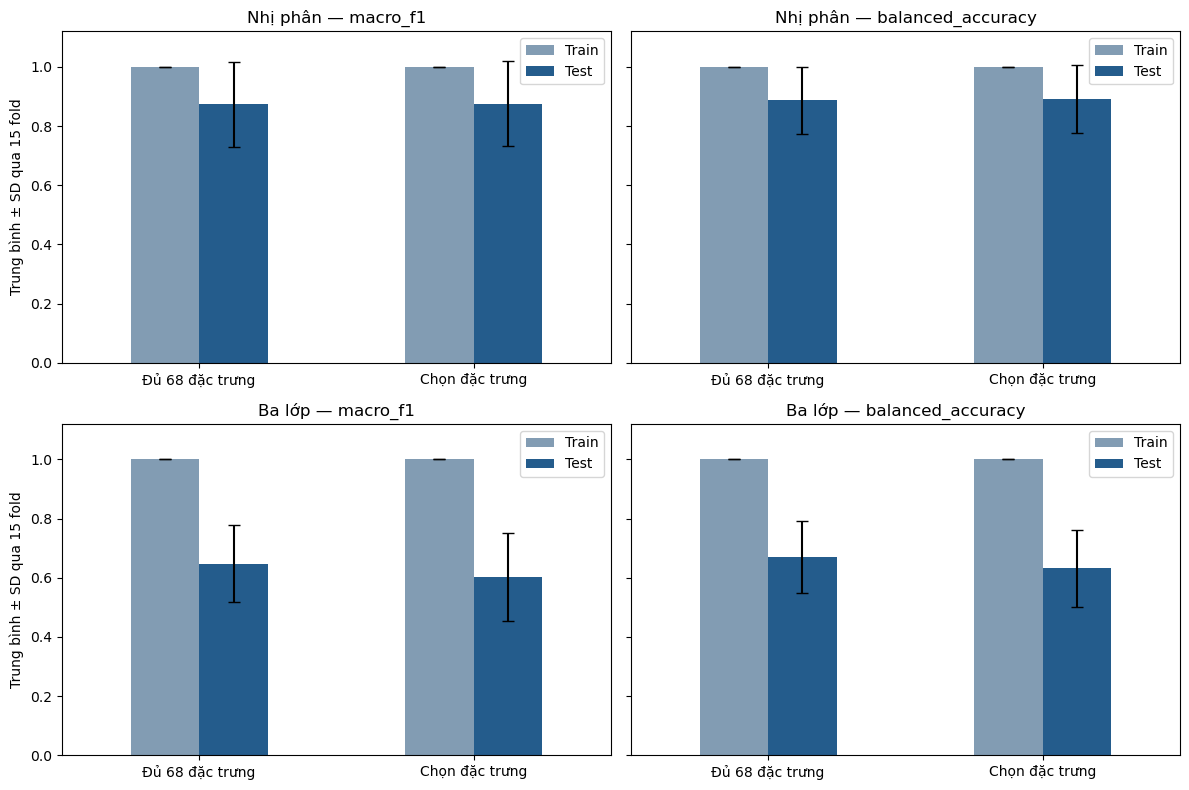

### Nhận xét train–test

- Nhị phân, Đủ 68 đặc trưng: train Macro-F1 1.0000; test Macro-F1 0.8735; khoảng cách 0.1265. Train BA 1.0000; test BA 0.8865.

- Nhị phân, Chọn đặc trưng: train Macro-F1 1.0000; test Macro-F1 0.8757; khoảng cách 0.1243. Train BA 1.0000; test BA 0.8902.

- Ba lớp, Đủ 68 đặc trưng: train Macro-F1 1.0000; test Macro-F1 0.6480; khoảng cách 0.3520. Train BA 1.0000; test BA 0.6700.

- Ba lớp, Chọn đặc trưng: train Macro-F1 1.0000; test Macro-F1 0.6024; khoảng cách 0.3976. Train BA 1.0000; test BA 0.6313.

Khoảng cách train–test mô tả mức chênh lệch giữa dữ liệu đã học và người giữ riêng. Khoảng cách lớn gợi ý cần xem xét overfitting và khác biệt giữa người; chưa đủ để xác định một nguyên nhân duy nhất. Đánh giá hiệu quả dựa trên cả điểm test và độ phân tán theo người.

In [12]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_TRAIN_TEST = False

here_tt = Path.cwd()
repo_tt = next(p for p in (here_tt, *here_tt.parents) if (p / 'src/wesad/evaluation.py').is_file())
package_tt = repo_tt / 'experiments/04_additional/EXP-019_RF'
source_tt = repo_tt / 'outputs/exp019_rf_mai_20261122'

if RUN_TRAIN_TEST:
    proof_tt = json.loads((source_tt / 'verification.json').read_text(encoding='utf-8'))
    assert proof_tt['status'] == 'passed' and proof_tt['outer_folds'] == 30
    scores_tt = pd.read_csv(source_tt / 'results.csv').rename(
        columns={'macro_f1': 'test_macro_f1', 'balanced_accuracy': 'test_balanced_accuracy'})
    assert len(scores_tt) == 60 and set(scores_tt.variant) == {'full68', 'selected'}
    assert not scores_tt.duplicated(['task', 'subject_id', 'variant']).any()
    assert set(scores_tt.task) == {'binary', 'multiclass'}
    assert all(len(g) == 15 and g.subject_id.nunique() == 15
               for _, g in scores_tt.groupby(['task', 'variant']))
    for metric in ['macro_f1', 'balanced_accuracy']:
        scores_tt[f'gap_{metric}'] = scores_tt[f'train_{metric}'] - scores_tt[f'test_{metric}']
    columns_tt = [f'{split}_{metric}' for metric in ['macro_f1', 'balanced_accuracy']
                  for split in ['train', 'test', 'gap']]
    assert scores_tt[columns_tt].notna().all().all()
    assert scores_tt[[c for c in columns_tt if not c.startswith('gap_')]].apply(
        lambda col: col.between(0, 1).all()).all()
    summary_tt = scores_tt.groupby(['task', 'variant'])[columns_tt].agg(['mean', 'std'])
    display(summary_tt.round(4))
    summary_tt.to_csv(package_tt / 'train_test_summary.csv')

    names_tt = {'binary': 'Nhị phân', 'multiclass': 'Ba lớp'}
    labels_tt = {'baseline': 'RF mặc định', 'balanced': 'RF cân bằng lớp',
                 'full68': 'Đủ 68 đặc trưng', 'selected': 'Chọn đặc trưng'}
    fig_tt, axes_tt = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    for row, task in enumerate(['binary', 'multiclass']):
        part_tt = scores_tt.loc[scores_tt.task.eq(task)]
        for col, metric in enumerate(['macro_f1', 'balanced_accuracy']):
            fields_tt = [f'train_{metric}', f'test_{metric}']
            means_tt = part_tt.groupby('variant')[fields_tt].mean()
            errors_tt = part_tt.groupby('variant')[fields_tt].std(ddof=1)
            means_tt = means_tt.rename(index=labels_tt, columns={fields_tt[0]: 'Train', fields_tt[1]: 'Test'})
            errors_tt = errors_tt.rename(index=labels_tt, columns={fields_tt[0]: 'Train', fields_tt[1]: 'Test'})
            means_tt.plot.bar(yerr=errors_tt, ax=axes_tt[row, col], rot=0, capsize=4,
                              color=['#829CB3', '#245C8C'])
            axes_tt[row, col].set_title(f'{names_tt[task]} — {metric}')
            axes_tt[row, col].set_ylim(0, 1.12)
            axes_tt[row, col].set_xlabel('')
            axes_tt[row, col].set_ylabel('Trung bình ± SD qua 15 fold')
    fig_tt.tight_layout()
    (package_tt / 'figures').mkdir(exist_ok=True)
    fig_tt.savefig(package_tt / 'figures/train_vs_test.png', dpi=150, bbox_inches='tight')
    plt.show()

    notes_tt = ['### Nhận xét train–test']
    for (task, variant), group_tt in scores_tt.groupby(['task', 'variant']):
        notes_tt.append(
            f'- {names_tt[task]}, {labels_tt[variant]}: train Macro-F1 '
            f'{group_tt.train_macro_f1.mean():.4f}; test Macro-F1 '
            f'{group_tt.test_macro_f1.mean():.4f}; khoảng cách '
            f'{group_tt.gap_macro_f1.mean():.4f}. Train BA '
            f'{group_tt.train_balanced_accuracy.mean():.4f}; test BA '
            f'{group_tt.test_balanced_accuracy.mean():.4f}.'
        )
    notes_tt.append('Khoảng cách train–test mô tả mức chênh lệch giữa dữ liệu đã học và người giữ riêng. '
                    'Khoảng cách lớn gợi ý cần xem xét overfitting và khác biệt giữa người; '
                    'chưa đủ để xác định một nguyên nhân duy nhất. '
                    'Đánh giá hiệu quả dựa trên cả điểm test và độ phân tán theo người.')
    display(Markdown('\n\n'.join(notes_tt)))
